In [1]:
import SimpleITK as sitk
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Configurations and Tools

In [2]:
csv_path = "/Users/furkan/projects/mebar-radiology/preprocessing/configurations/no_alignment/pipeline_checkpoints.csv"

In [3]:
from IPython.display import display, HTML


# render a dataframe fully (no pandas ellipsis) inside a scrollable container
def show_scrollable(df, max_height="300px"):
    display(HTML(f'<div style="max-height:{max_height}; overflow:auto; border:1px solid #999">{df.to_html()}</div>'))

# Exploration

In [4]:
STAGE = "after_pad"
csv_df = pd.read_csv(csv_path)
csv_df = csv_df[csv_df["stage"] == STAGE].reset_index(drop=True)
csv_df.head()

,stage,sample_id,modality,image_out_path,mask_out_path,image_shape_x,image_shape_y,image_shape_z,image_spacing_x,image_spacing_y,...,mask_shape_y,mask_shape_z,mask_spacing_x,mask_spacing_y,mask_spacing_z,mask_mm_x,mask_mm_y,mask_mm_z,mask_voxels,mask_volume_mm3
0,after_pad,0d6f73a01539ae0d,ADC,/Users/furkan/projects/mebar-radiology/preproc...,/Users/furkan/projects/mebar-radiology/preproc...,42,52,15,1.3,1.3,...,52,15,1.3,1.3,4.6,54.6,67.6,69.0,32760,254676.24
1,after_pad,85388bd87a565011,T2,/Users/furkan/projects/mebar-radiology/preproc...,/Users/furkan/projects/mebar-radiology/preproc...,108,136,17,0.5,0.5,...,136,17,0.5,0.5,4.1,54.0,68.0,69.7,249696,255938.40
2,after_pad,c5574c732708c9c0,ADC,/Users/furkan/projects/mebar-radiology/preproc...,/Users/furkan/projects/mebar-radiology/preproc...,42,52,15,1.3,1.3,...,52,15,1.3,1.3,4.6,54.6,67.6,69.0,32760,254676.24
3,after_pad,d4e511f387bc2059,T2,/Users/furkan/projects/mebar-radiology/preproc...,/Users/furkan/projects/mebar-radiology/preproc...,108,136,17,0.5,0.5,...,136,17,0.5,0.5,4.1,54.0,68.0,69.7,249696,255938.40
4,after_pad,85e3e9f712fe9029,ADC,/Users/furkan/projects/mebar-radiology/preproc...,/Users/furkan/projects/mebar-radiology/preproc...,42,52,15,1.3,1.3,...,52,15,1.3,1.3,4.6,54.6,67.6,69.0,32760,254676.24


In [5]:
adc_df = csv_df[csv_df["modality"] == "ADC"]
t2_df = csv_df[csv_df["modality"] == "T2"]

In [6]:
adc_df.describe()

,image_shape_x,image_shape_y,image_shape_z,image_spacing_x,image_spacing_y,image_spacing_z,image_mm_x,image_mm_y,image_mm_z,image_voxels,...,mask_shape_y,mask_shape_z,mask_spacing_x,mask_spacing_y,mask_spacing_z,mask_mm_x,mask_mm_y,mask_mm_z,mask_voxels,mask_volume_mm3
count,187.0,187.0,187.0,187.0,187.0,1.870000e+02,1.870000e+02,1.870000e+02,187.0,187.0,...,187.0,187.0,187.0,187.0,1.870000e+02,1.870000e+02,1.870000e+02,187.0,187.0,1.870000e+02
mean,42.0,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,...,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,2.546762e+05
std,0.0,0.0,0.0,0.0,0.0,1.781126e-15,2.137351e-14,1.424900e-14,0.0,0.0,...,0.0,0.0,0.0,0.0,1.781126e-15,2.137351e-14,1.424900e-14,0.0,0.0,5.836392e-11
min,42.0,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,...,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,2.546762e+05
25%,42.0,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,...,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,2.546762e+05
50%,42.0,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,...,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,2.546762e+05
75%,42.0,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,...,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,2.546762e+05
max,42.0,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,...,52.0,15.0,1.3,1.3,4.600000e+00,5.460000e+01,6.760000e+01,69.0,32760.0,2.546762e+05


In [7]:
t2_df.describe()

,image_shape_x,image_shape_y,image_shape_z,image_spacing_x,image_spacing_y,image_spacing_z,image_mm_x,image_mm_y,image_mm_z,image_voxels,...,mask_shape_y,mask_shape_z,mask_spacing_x,mask_spacing_y,mask_spacing_z,mask_mm_x,mask_mm_y,mask_mm_z,mask_voxels,mask_volume_mm3
count,188.0,188.0,188.0,188.0,188.0,1.880000e+02,188.0,188.0,1.880000e+02,188.0,...,188.0,188.0,188.0,188.0,1.880000e+02,188.0,188.0,1.880000e+02,188.0,1.880000e+02
mean,108.0,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,...,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,2.559384e+05
std,0.0,0.0,0.0,0.0,0.0,8.905501e-16,0.0,0.0,1.424880e-14,0.0,...,0.0,0.0,0.0,0.0,8.905501e-16,0.0,0.0,1.424880e-14,0.0,2.918154e-11
min,108.0,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,...,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,2.559384e+05
25%,108.0,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,...,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,2.559384e+05
50%,108.0,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,...,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,2.559384e+05
75%,108.0,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,...,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,2.559384e+05
max,108.0,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,...,136.0,17.0,0.5,0.5,4.100000e+00,54.0,68.0,6.970000e+01,249696.0,2.559384e+05


In [8]:
# visualize every numeric feature, 3 histograms per row
# stage, sample_id, modality and path columns are not features and stay out of the grid
def visualize_after_crop(modality):
    modality_df = csv_df[csv_df["modality"] == modality]
    excluded_cols = {"stage", "sample_id", "modality", "image_out_path", "mask_out_path", "image_voxels", "mask_voxels"}
    numeric_cols = [col for col in modality_df.columns if col not in excluded_cols and modality_df[col].dtype != object]

    # keep x/y/z features sharing the same base name together in one row
    volume_cols = [col for col in numeric_cols if col.endswith("volume_mm3")]
    ordered_cols = []
    for col in numeric_cols:
        if col in volume_cols or col[-1] != "x":
            continue
        base = col[:-2]
        ordered_cols.extend(f"{base}_{axis}" for axis in "xyz" if f"{base}_{axis}" in numeric_cols)
    ordered_cols += volume_cols  # volumes come last

    grid_cols = 3
    grid_rows = int(np.ceil(len(ordered_cols) / grid_cols))

    fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(15, 4 * grid_rows))

    for ax, col in zip(axes.flat, ordered_cols):
        ax.hist(modality_df[col], bins=30)
        ax.set_title(f"{col} ({modality})")

    for ax in axes.flat[len(ordered_cols):]:
        ax.set_visible(False)

    fig.tight_layout()
    plt.show()


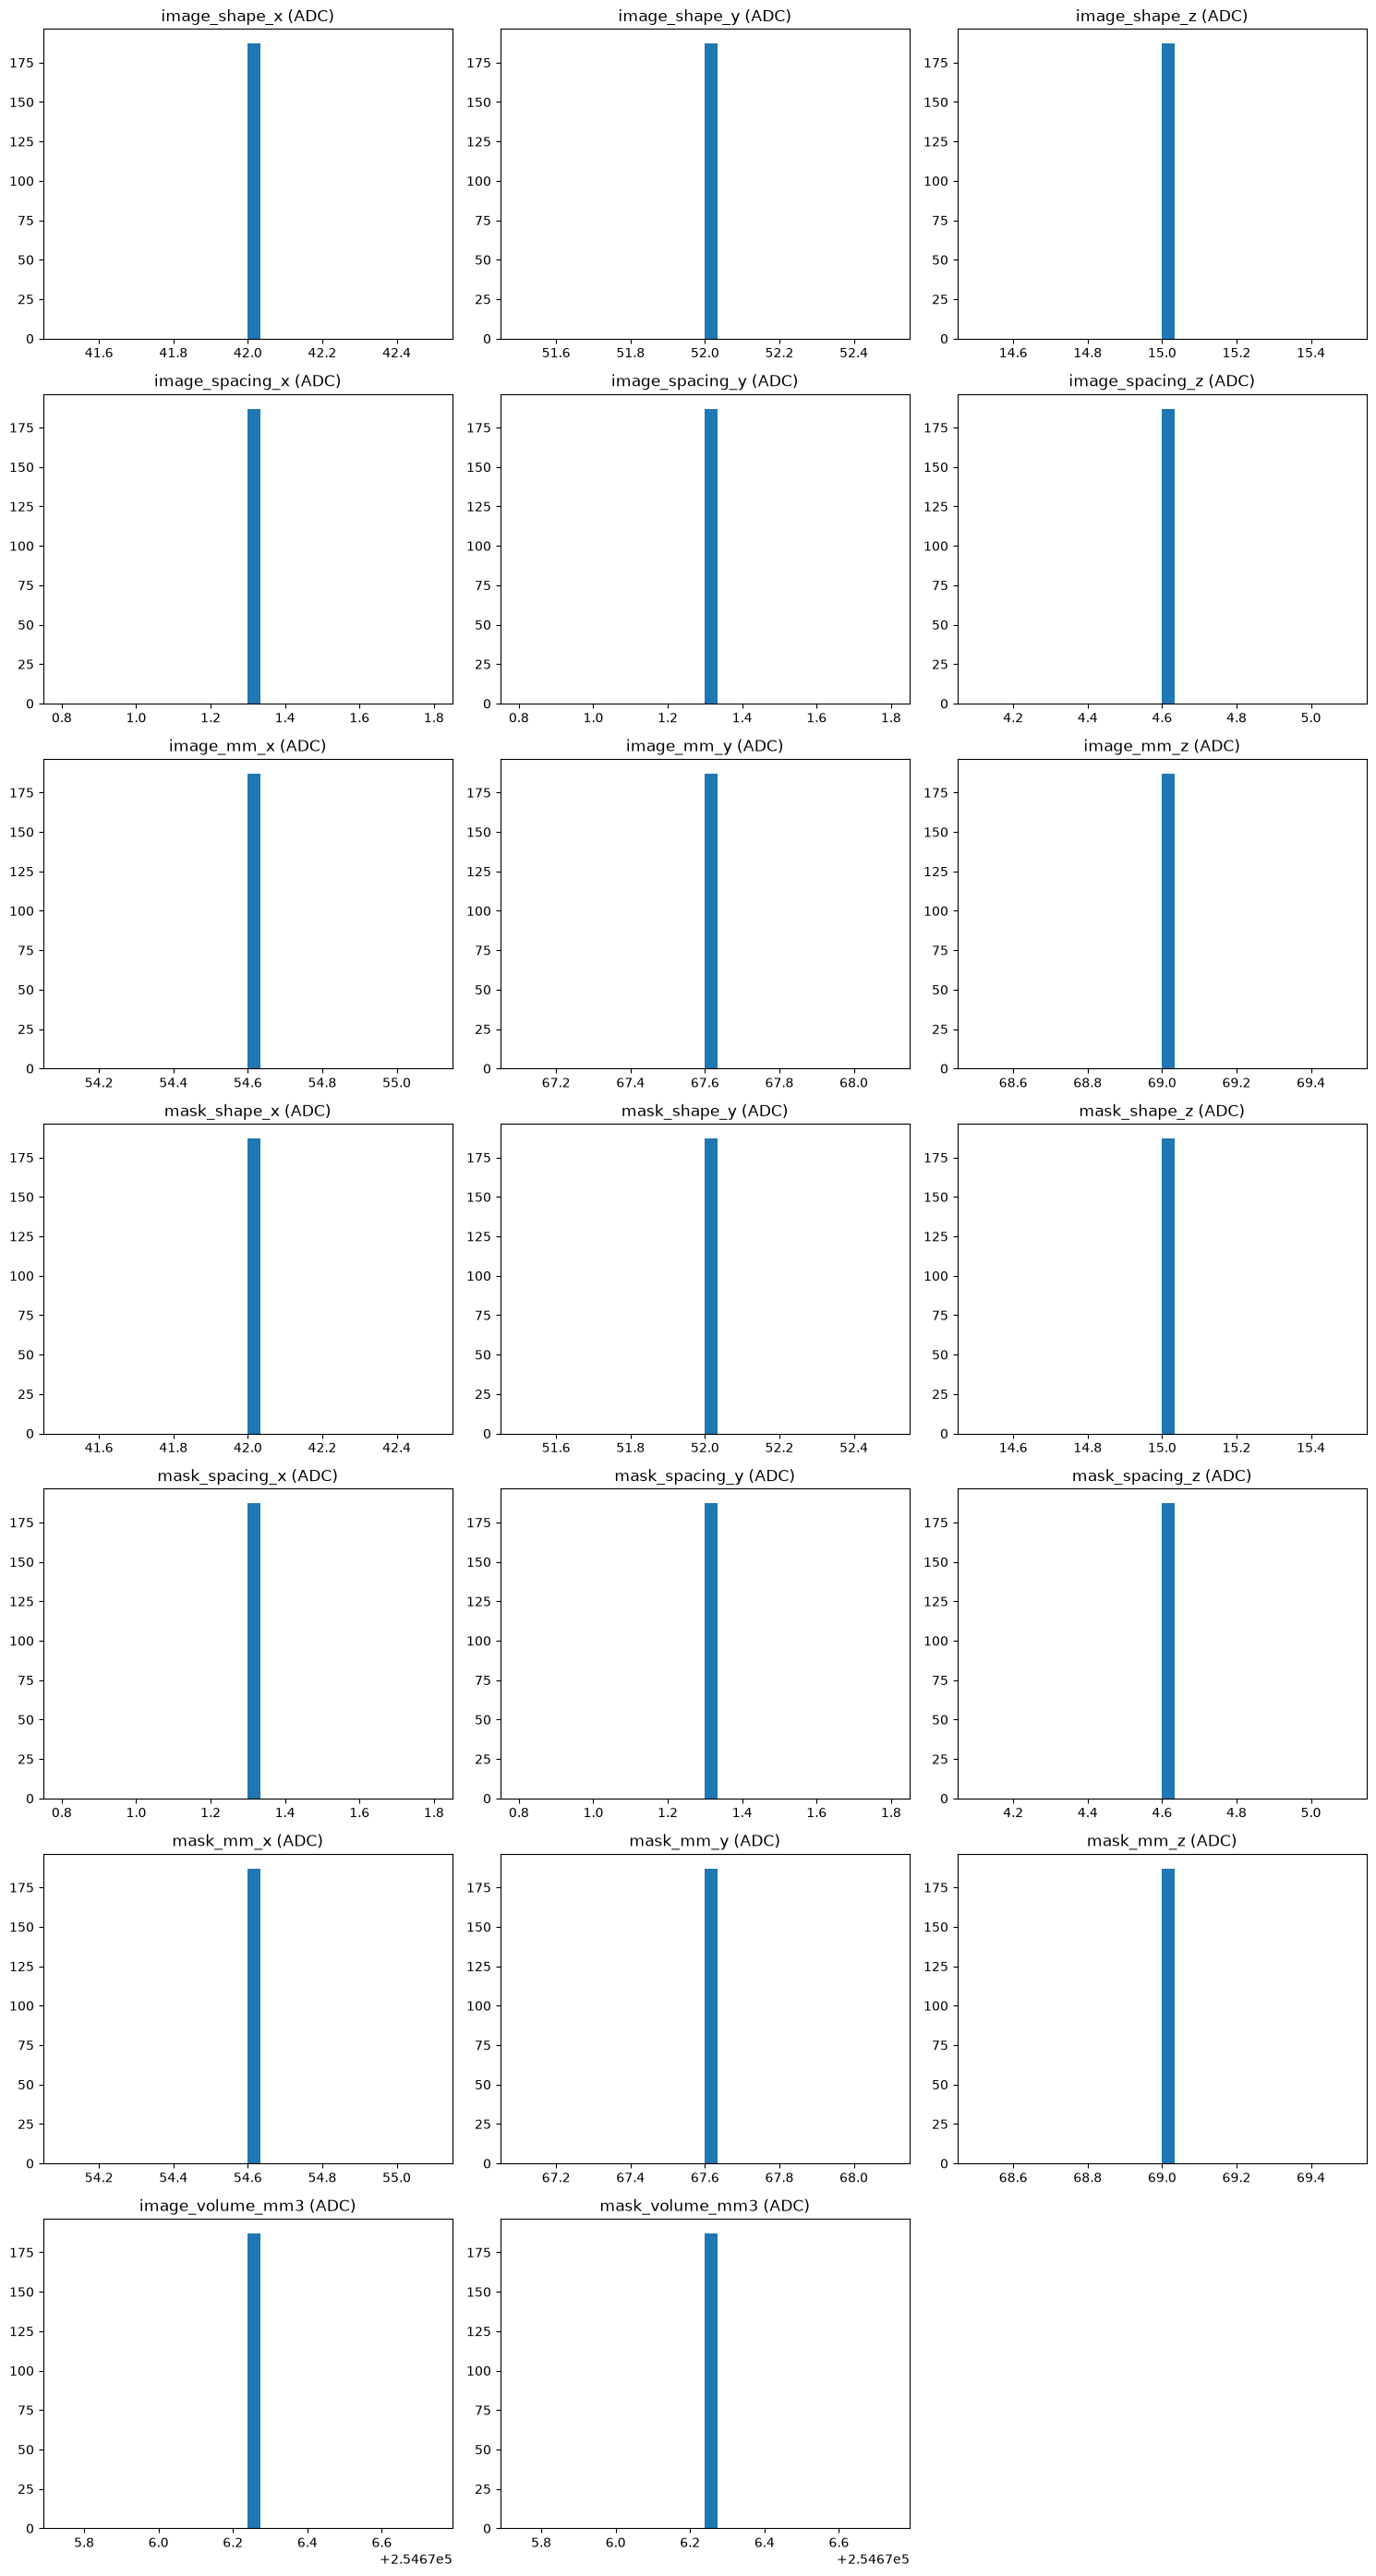

In [9]:
visualize_after_crop("ADC")

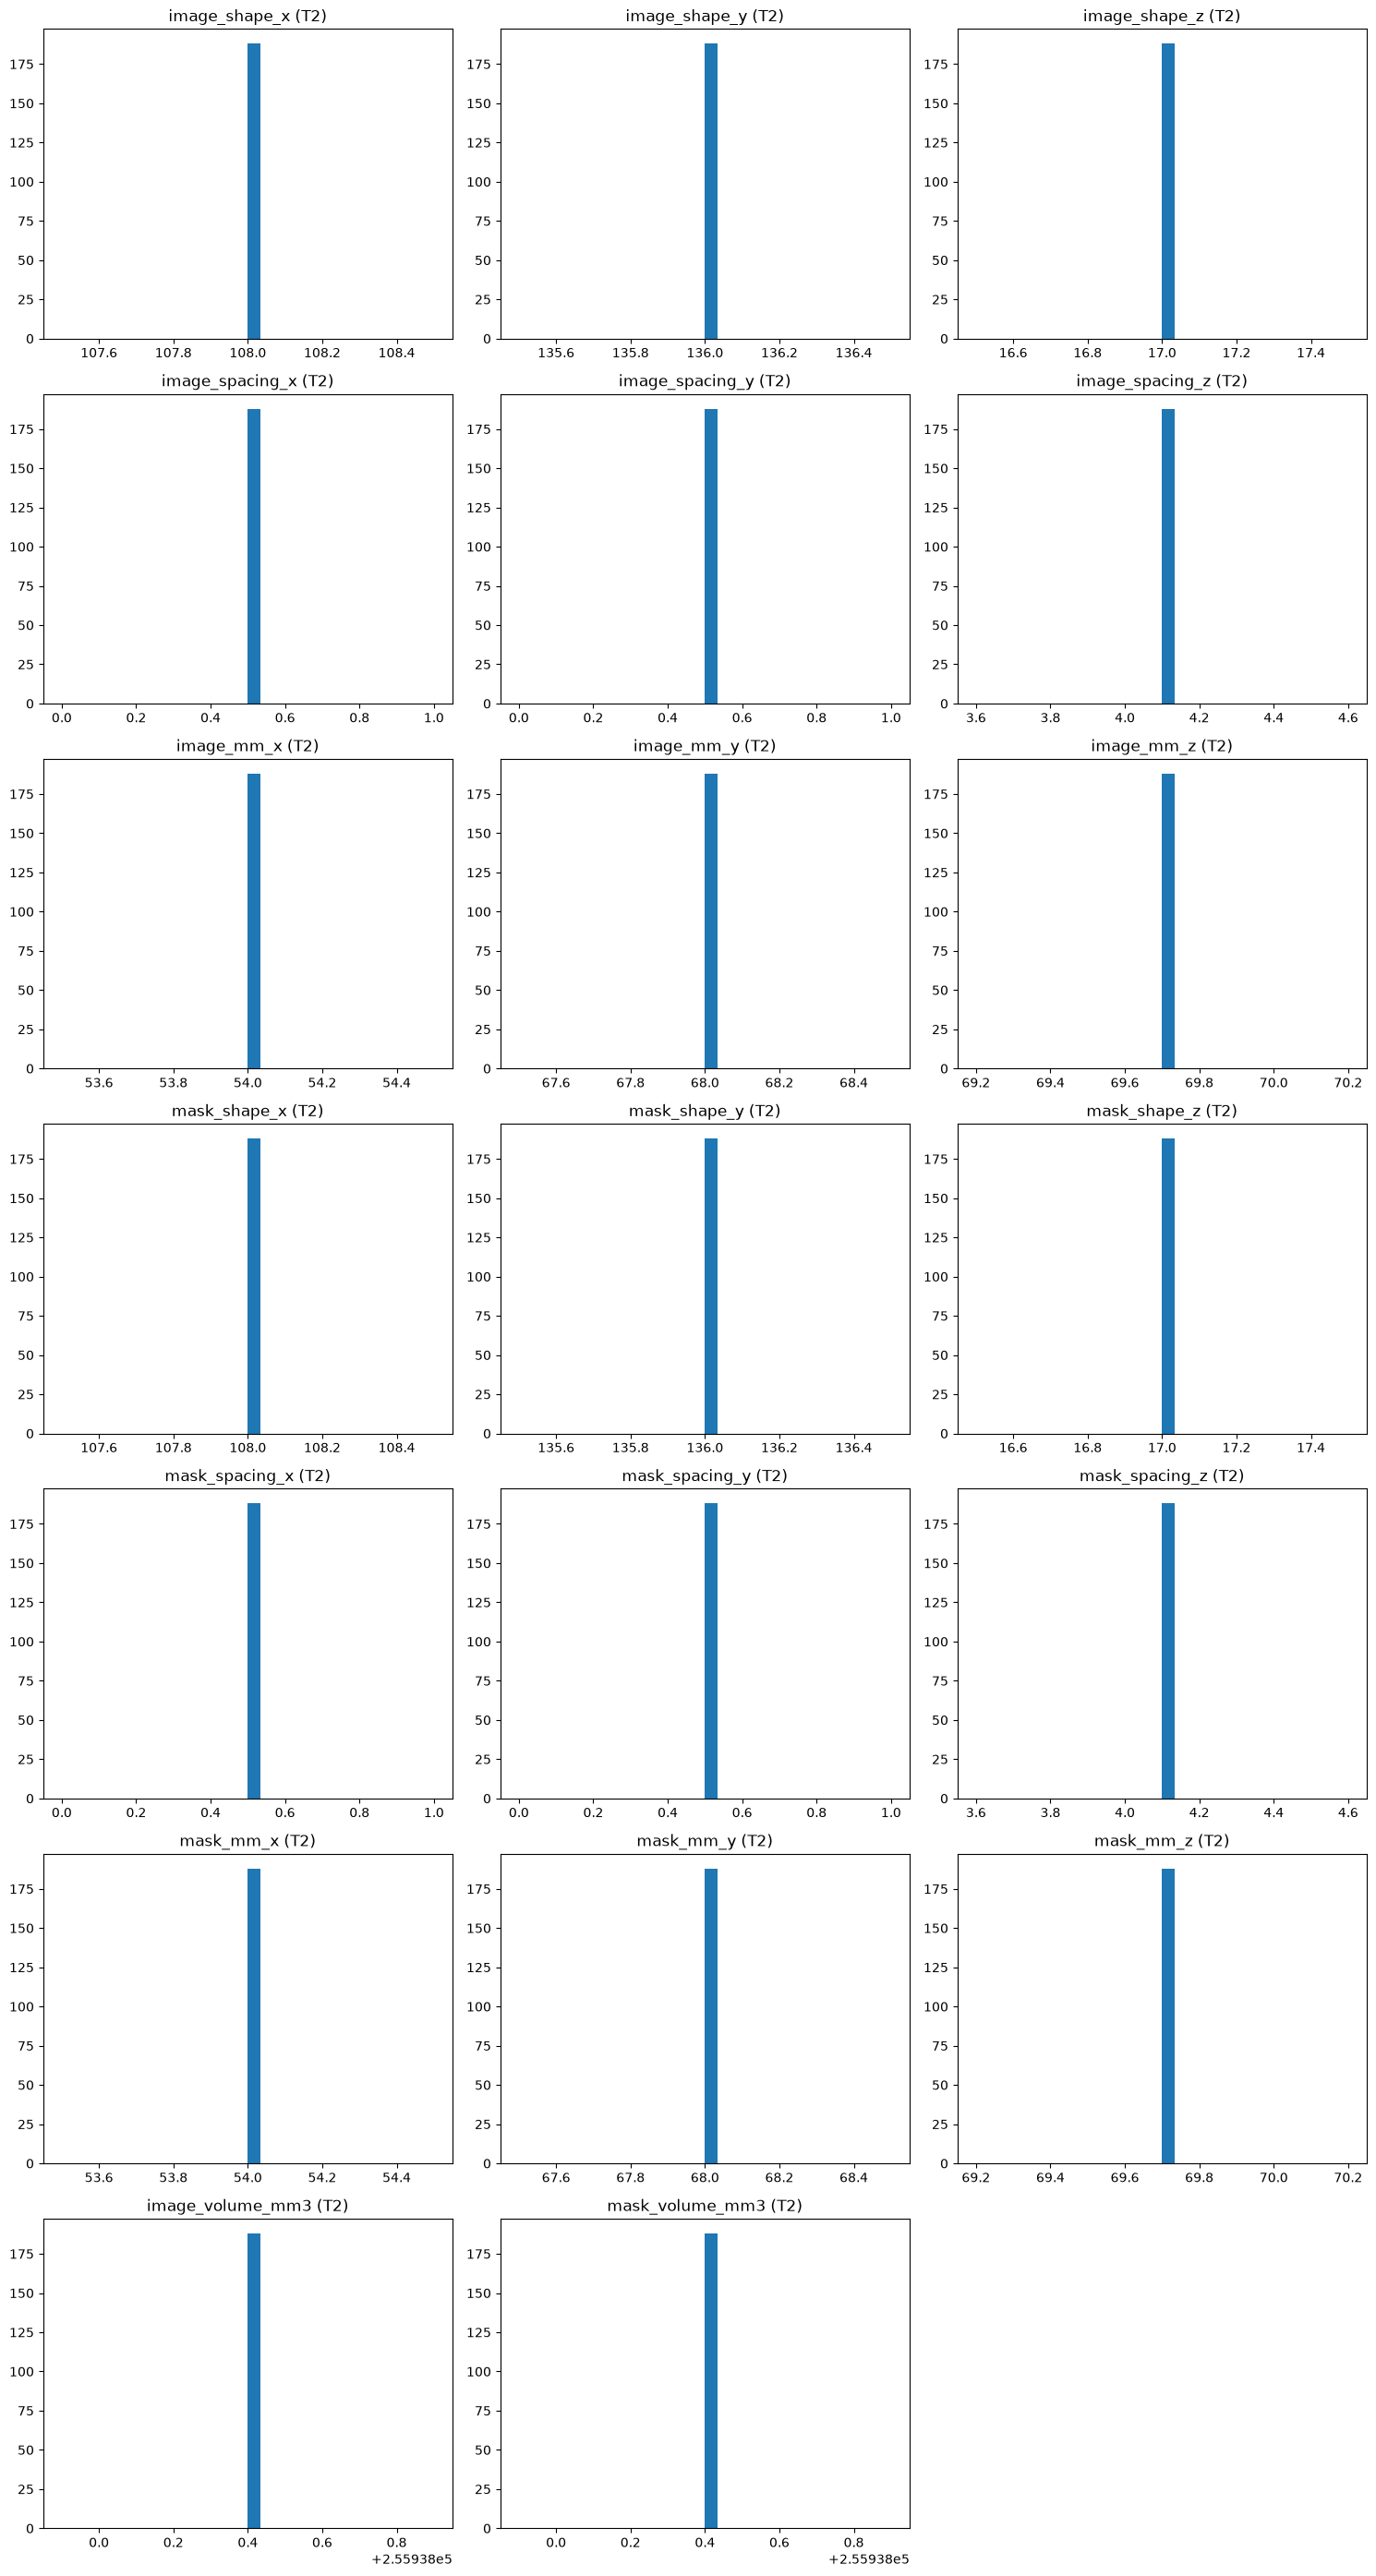

In [10]:
visualize_after_crop("T2")

In [11]:
# outlier detection: for every numeric feature, samples deviating from the most frequent value
def find_outlier_samples(modality):
    modality_df = csv_df[csv_df["modality"] == modality]
    excluded_cols = {"stage", "sample_id", "modality", "image_out_path", "mask_out_path", "image_voxels", "mask_voxels"}
    numeric_cols = [col for col in modality_df.columns if col not in excluded_cols and modality_df[col].dtype != object]

    outlier_sets = {}  # feature -> set of sample_ids whose value differs from the feature's mode
    mode_rows = []
    for col in numeric_cols:
        mode_value = modality_df[col].mode()[0]
        mode_rows.append({"feature": col, "most_frequent_value": mode_value})
        deviating = set(modality_df.loc[modality_df[col] != mode_value, "sample_id"])
        if deviating:
            outlier_sets[col] = deviating

    show_scrollable(pd.DataFrame(mode_rows))

    # intersection: samples that deviate in every feature that has any deviation
    common_outliers = set.intersection(*outlier_sets.values()) if outlier_sets else set()
    if not common_outliers:
        return pd.DataFrame(columns=["sample_id", "n_outlier_features", "outlier_features"])

    outlier_df = pd.DataFrame(
        [
            {"sample_id": sample_id, "n_outlier_features": len(features), "outlier_features": sorted(features)}
            for sample_id in common_outliers
            for features in [[col for col, ids in outlier_sets.items() if sample_id in ids]]
        ]
    ).sort_values("n_outlier_features", ascending=False).reset_index(drop=True)
    return outlier_df

In [12]:
show_scrollable(find_outlier_samples("ADC"))

,feature,most_frequent_value
0,image_shape_x,42.00
1,image_shape_y,52.00
2,image_shape_z,15.00
3,image_spacing_x,1.30
4,image_spacing_y,1.30
5,image_spacing_z,4.60
6,image_mm_x,54.60
7,image_mm_y,67.60
8,image_mm_z,69.00
9,image_volume_mm3,254676.24


,sample_id,n_outlier_features,outlier_features


In [13]:
show_scrollable(find_outlier_samples("T2"))

,feature,most_frequent_value
0,image_shape_x,108.0
1,image_shape_y,136.0
2,image_shape_z,17.0
3,image_spacing_x,0.5
4,image_spacing_y,0.5
5,image_spacing_z,4.1
6,image_mm_x,54.0
7,image_mm_y,68.0
8,image_mm_z,69.7
9,image_volume_mm3,255938.4


,sample_id,n_outlier_features,outlier_features


In [14]:
show_scrollable(
	pd.concat([
	t2_df[t2_df["sample_id"] == "0660e38133ac7e28"],
	t2_df[t2_df["sample_id"] == "0e393767a07522dc"]
	])
)

,stage,sample_id,modality,image_out_path,mask_out_path,image_shape_x,image_shape_y,image_shape_z,image_spacing_x,image_spacing_y,image_spacing_z,image_mm_x,image_mm_y,image_mm_z,image_voxels,image_volume_mm3,mask_shape_x,mask_shape_y,mask_shape_z,mask_spacing_x,mask_spacing_y,mask_spacing_z,mask_mm_x,mask_mm_y,mask_mm_z,mask_voxels,mask_volume_mm3
276,after_pad,0660e38133ac7e28,T2,/Users/furkan/projects/mebar-radiology/preprocessing/configurations/no_alignment/images/0660e38133ac7e28_T2.nrrd,/Users/furkan/projects/mebar-radiology/preprocessing/configurations/no_alignment/images/0660e38133ac7e28_mask.nrrd,108,136,17,0.5,0.5,4.1,54.0,68.0,69.7,249696,255938.4,108,136,17,0.5,0.5,4.1,54.0,68.0,69.7,249696,255938.4
64,after_pad,0e393767a07522dc,T2,/Users/furkan/projects/mebar-radiology/preprocessing/configurations/no_alignment/images/0e393767a07522dc_T2.nrrd,/Users/furkan/projects/mebar-radiology/preprocessing/configurations/no_alignment/images/0e393767a07522dc_mask.nrrd,108,136,17,0.5,0.5,4.1,54.0,68.0,69.7,249696,255938.4,108,136,17,0.5,0.5,4.1,54.0,68.0,69.7,249696,255938.4


In [15]:
# count voxels equal to 1 in every tumor mask
def count_tumor_voxels():
    rows = []
    for sample_id, mask_path in zip(csv_df["sample_id"], csv_df["mask_out_path"]):
        mask = sitk.GetArrayFromImage(sitk.ReadImage(mask_path))
        rows.append({"sample_id": sample_id, "voxel_count": int((mask == 1).sum())})
    return pd.DataFrame(rows)

tumor_voxels_count_df = count_tumor_voxels()

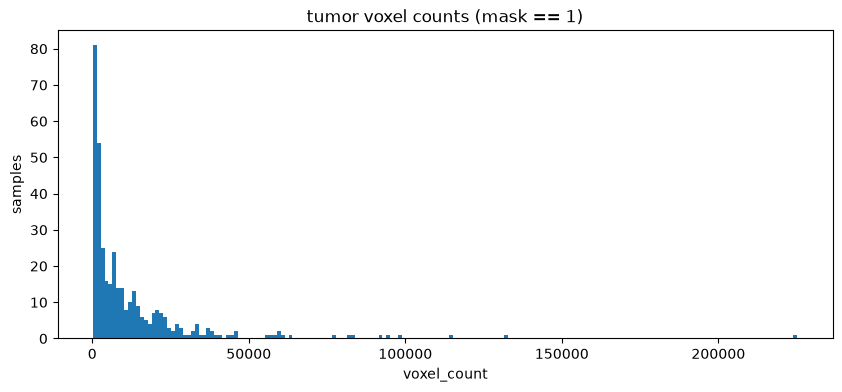

In [16]:
plt.figure(figsize=(10, 4))
plt.hist(tumor_voxels_count_df["voxel_count"], bins=180)
plt.xlabel("voxel_count")
plt.ylabel("samples")
plt.title("tumor voxel counts (mask == 1)")
plt.show()

In [17]:
tumor_voxels_count_df.describe()

,voxel_count
count,375.000000
mean,12518.298667
std,20659.656266
min,190.000000
25%,1659.000000
50%,5997.000000
75%,15035.000000
max,225248.000000


In [18]:
pd.concat(
	[tumor_voxels_count_df[tumor_voxels_count_df["sample_id"] == "0e393767a07522dc"],
	tumor_voxels_count_df[tumor_voxels_count_df["sample_id"] == "0660e38133ac7e28"]]
)


,sample_id,voxel_count
64,0e393767a07522dc,2557
276,0660e38133ac7e28,7173
